# 03 · Flow matching, learned transport and numerical solvers

Begin with endpoint pairs, derive a marginal velocity, then learn a field and compare integration cost.

**Prerequisites:** 00–02; ODEs, MSE and conditional expectation.

**By the end:** Distinguish straight training pairs from curved marginal paths; train a flow; compare Euler/Heun/RK4/RK45 by actual field calls; explore interpolation and reflow.

Run from top to bottom. Default experiments use CPU, fixed seeds and no downloads. Small trained models illustrate learning; analytic oracles isolate mathematical and solver effects. Neither is an image-quality benchmark.

[Course index](README.md) · [Notation](../docs/23_notation_and_code.md) · [Implementation scope](../docs/15_coverage_and_scope.md)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

project = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "diffusion_lab").is_dir())
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
torch.set_num_threads(2)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update(
    {
        "figure.figsize": (10, 3.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.dpi": 100,
    }
)
ENABLE_WIDGETS = False  # Set True in Jupyter; static figures work on GitHub.
print(f"PyTorch {torch.__version__}; CPU lesson; seed=7; no automatic downloads.")


def scatter(ax, samples, title, labels=None, limits=(-4.5, 4.5)):
    points = samples.detach().cpu().numpy()
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    ax.scatter(
        points[:, 0],
        points[:, 1],
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=5,
        alpha=0.55,
        linewidths=0,
    )
    ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", aspect="equal", xlim=limits, ylim=limits)


def saved_gallery(relative, caption):
    path = project / relative
    if not path.is_file():
        raise FileNotFoundError(f"Missing curated course evidence: {relative}")
    print(caption)
    display(Image(filename=str(path)))


def animate_particles(history, name, title, labels=None, limits=(-4.5, 4.5)):
    from matplotlib.animation import FuncAnimation, PillowWriter

    points = history.detach().cpu().numpy()
    indices = np.linspace(0, len(points) - 1, min(32, len(points))).astype(int)
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    colors = labels.detach().cpu().numpy() if labels is not None else "steelblue"
    dots = ax.scatter(
        *points[0].T,
        c=colors,
        cmap="tab10" if labels is not None else None,
        s=9,
        alpha=0.65,
        linewidths=0,
    )
    ax.set(xlim=limits, ylim=limits, aspect="equal", xlabel="$x_1$", ylabel="$x_2$")

    def update(frame):
        dots.set_offsets(points[indices[frame]])
        ax.set_title(f"{title}: frame {frame + 1}/{len(indices)}")
        return (dots,)

    animation = FuncAnimation(fig, update, frames=len(indices), interval=100)
    folder = project / "assets/teaching/notebooks"
    folder.mkdir(parents=True, exist_ok=True)
    target = folder / f"{name}.gif"
    animation.save(target, writer=PillowWriter(fps=10), dpi=75)
    plt.close(fig)
    display(Image(filename=str(target)))

PyTorch 2.7.1+cu128; CPU lesson; seed=7; no automatic downloads.


## 1. Generation time goes noise → data

Use $\tau\in[0,1]$, source noise $Z$ and data $X$:
$$I_\tau=(1-\tau)Z+\tau X,\quad \dot I_\tau=X-Z,$$
$$\mathcal L=\mathbb E\|u_\theta(I_\tau,\tau)-(X-Z)\|^2.$$
The optimum is $u_\tau(x)=\mathbb E[X-Z|I_\tau=x]$, which satisfies continuity.
Straight endpoint-pair paths can cross; the averaged field's ODE trajectories
need not be straight. Under usual uniqueness assumptions, ODE trajectories
cannot cross at the same time. VP-v from 01 is not this derivative.
**Code:** `flow_coefficients` in [paths.py](../diffusion_lab/paths.py), training in [train.py](../diffusion_lab/train.py).

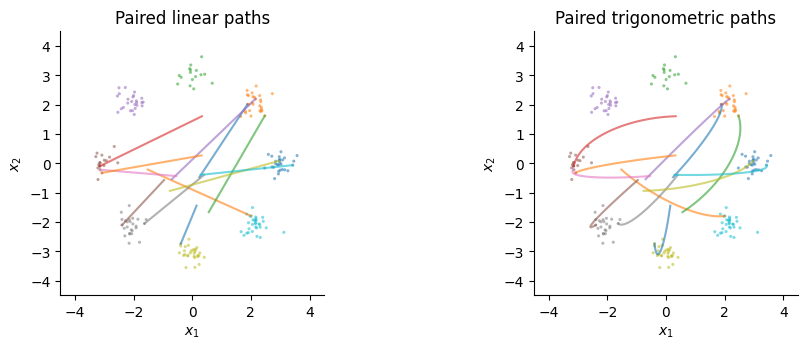

In [2]:
from diffusion_lab.data import GaussianMixture
from diffusion_lab.models import Conditioning, TimeMLP
from diffusion_lab.paths import expand, flow_coefficients
from diffusion_lab.solvers import integrate

g = torch.Generator().manual_seed(41)
source = torch.randn(200, 2, generator=g)
mixture = GaussianMixture()
target, labels = mixture.sample(200, g)
grid = torch.linspace(0, 1, 51)
fig, axes = plt.subplots(1, 2)
for ax, kind in zip(axes, ["linear", "trigonometric"], strict=True):
    history = []
    for time in grid:
        a, s, da, ds = flow_coefficients(time.repeat(len(source)), kind)
        history.append(expand(a, target) * target + expand(s, source) * source)
    history = torch.stack(history)
    ax.plot(history[:, :12, 0], history[:, :12, 1], alpha=0.6)
    scatter(ax, target, f"Paired {kind} paths", labels)
plt.tight_layout()
plt.show()

## 2. An exact Gaussian flow separates solver error from model error

For independent $Z\sim N(0,I)$, $X\sim N(\mu,\operatorname{diag}(s_1^2))$,
$I_\tau$ has mean $\tau\mu$ and variance $q=(1-\tau)^2+\tau^2s_1^2$.
$$u_\tau(x)=\mu+\frac{-(1-\tau)+\tau s_1^2}{q}(x-\tau\mu).$$
The exact marginal ODE map at time $\tau$ is $\tau\mu+\sqrt q Z$;
at 1 it is $\mu+s_1Z$. This map is **not** the original independent pair.
Euler uses 1 call/step, Heun 2, RK4 4. RK45 chooses internal steps adaptively;
requested output times do not specify its call count.
**Code:** [solvers.py](../diffusion_lab/solvers.py).

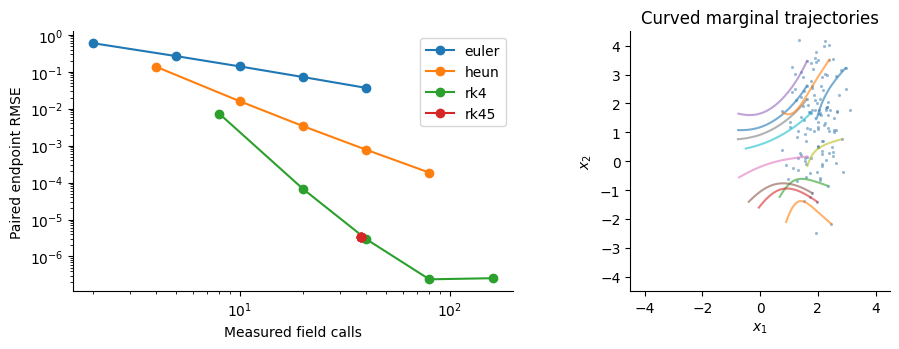

RK45 call counts: [38, 38, 38, 38, 38]


In [3]:
mean, std = torch.tensor([2.0, 1.0]), torch.tensor([0.5, 1.5])
initial = torch.randn(128, 2, generator=torch.Generator().manual_seed(42))


def gaussian_field(x, t):
    time = t[:, None]
    variance = (1 - time) ** 2 + time**2 * std.square()
    return mean + (-(1 - time) + time * std.square()) / variance * (x - time * mean)


exact = mean + std * initial
fig, axes = plt.subplots(1, 2)
records = []
for method in ["euler", "heun", "rk4", "rk45"]:
    costs, errors = [], []
    for steps in [2, 5, 10, 20, 40]:
        counter = {"calls": 0}

        def counted_field(x, t, counter=counter):
            counter["calls"] += 1
            return gaussian_field(x, t)

        out, history = integrate(counted_field, initial, torch.linspace(0, 1, steps + 1), method)
        error = (out - exact).square().mean().sqrt().item()
        costs.append(counter["calls"])
        errors.append(error)
        records.append((method, steps, counter["calls"], error))
    axes[0].loglog(costs, errors, marker="o", label=method)
axes[0].set(xlabel="Measured field calls", ylabel="Paired endpoint RMSE")
axes[0].legend()
_, history = integrate(gaussian_field, initial, torch.linspace(0, 1, 101), "heun")
axes[1].plot(history[:, :12, 0], history[:, :12, 1], alpha=0.6)
scatter(axes[1], exact, "Curved marginal trajectories")
plt.tight_layout()
plt.show()
print("RK45 call counts:", [row[2] for row in records if row[0] == "rk45"])

## 3. Learn the mixture velocity

No score network is needed for deterministic flow matching. Use a smooth positional embedding for normalized time. Draw new independent
endpoints at every update and regress their derivative. Below we use a small
unconditional CPU model; the full [flow recipe](../configs/experiment/gmm_flow.yaml)
adds saved training state and evaluation. Plot held-out samples instead of using loss as a quality claim.

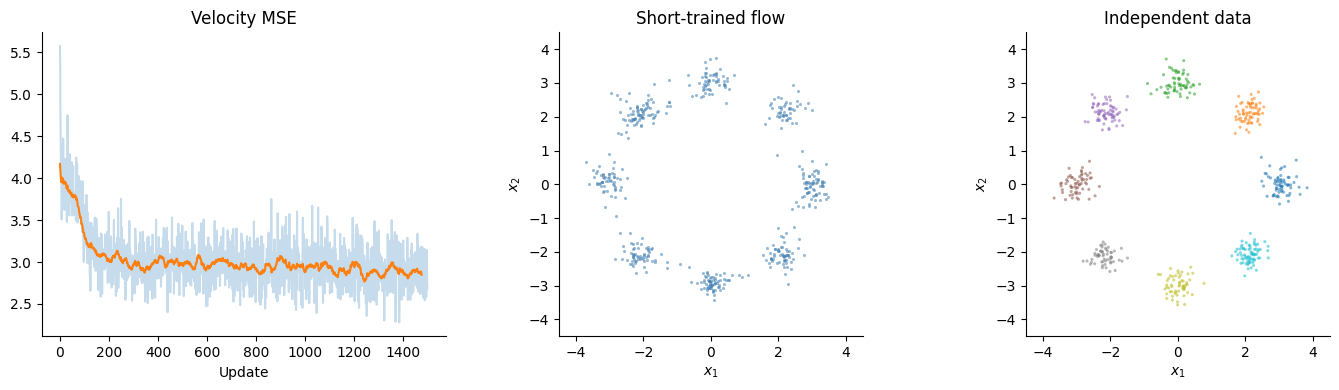

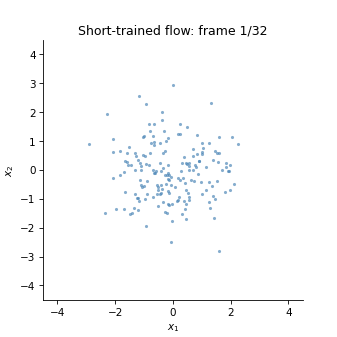

In [4]:
torch.manual_seed(43)
flow = TimeMLP(width=64, depth=2)
flow.condition = Conditioning(64, 0, time_embedding="positional")
optimizer = torch.optim.Adam(flow.parameters(), lr=0.002)
g = torch.Generator().manual_seed(43)
losses = []
for _step in range(1500):
    data, _ = mixture.sample(256, g)
    noise = torch.randn(data.shape, generator=g)
    time = torch.rand(len(data), generator=g)
    a, s, da, ds = flow_coefficients(time)
    state = expand(a, data) * data + expand(s, data) * noise
    velocity_target = expand(da, data) * data + expand(ds, data) * noise
    loss = (flow(state, time) - velocity_target).square().mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
flow.eval()
initial = torch.randn(512, 2, generator=torch.Generator().manual_seed(44))
generated, learned_history = integrate(flow, initial, torch.linspace(0, 1, 51), "heun")
reference, ref_labels = mixture.sample(512, torch.Generator().manual_seed(45))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(losses, alpha=0.25)
axes[0].plot(np.convolve(losses, np.ones(25) / 25, mode="valid"))
axes[0].set(title="Velocity MSE", xlabel="Update")
scatter(axes[1], generated, "Short-trained flow")
scatter(axes[2], reference, "Independent data", ref_labels)
plt.tight_layout()
plt.show()
animate_particles(learned_history[:, :180], "03_learned_flow", "Short-trained flow")

## 4. Noise interpolation and reflow are different operations

Interpolating two initial noise vectors explores a fixed generator's map.
Linear interpolation reduces variance at its midpoint: independent standard
Gaussian endpoints give variance $1/2$ there. Spherical interpolation approximately
maintains typical radius in high dimensions; neither promises semantic linearity.
This low-dimensional example intentionally uses simple linear interpolation.

Reflow instead generates teacher endpoints from known initial noise, then
trains a new field on those pairs. It can reduce trajectory curvature, but a
trained finite model need not improve every metric or become globally optimal transport.
**Implementation:** `reflow_checkpoint` in [train.py](../diffusion_lab/train.py),
[recipe](../configs/experiment/gmm_reflow.yaml).

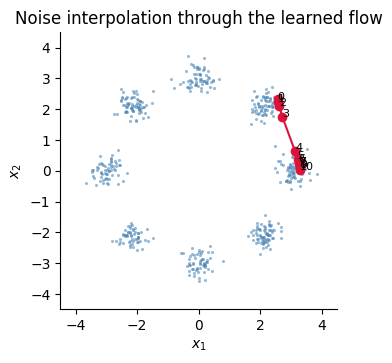

Mean squared trajectory-to-chord deviation: 0.14934277534484863


In [5]:
z0, z1 = initial[0], initial[1]
fractions = torch.linspace(0, 1, 11)
latent_line = (1 - fractions[:, None]) * z0 + fractions[:, None] * z1
decoded, _ = integrate(flow, latent_line, torch.linspace(0, 1, 51), "heun")
fig, ax = plt.subplots()
scatter(ax, reference, "Noise interpolation through the learned flow")
ax.plot(decoded[:, 0], decoded[:, 1], "o-", color="crimson")
for i, p in enumerate(decoded):
    ax.annotate(str(i), p.numpy(), fontsize=8)
plt.show()
# Chord deviation: zero only for a trajectory linear in this time parameter.
tau = torch.linspace(0, 1, len(learned_history))[:, None, None]
chord = (1 - tau) * learned_history[0] + tau * learned_history[-1]
print(
    "Mean squared trajectory-to-chord deviation:",
    (learned_history - chord).square().sum(-1).mean().item(),
)

## 5. Perform one small reflow round

Generate endpoint pairs with the fixed learned teacher, then fit a new linear
pair-path velocity. The source endpoints are known teacher initial noise;
the target endpoints come from integrating the teacher, not independent data draws.
Both fields below are evaluated on **new shared noise**. Compare curvature and
few-call samples instead of assuming rectification succeeds at a finite budget.

Original learned flow mean squared chord deviation: 0.009524120949208736
One short reflow round mean squared chord deviation: 0.0016569886356592178


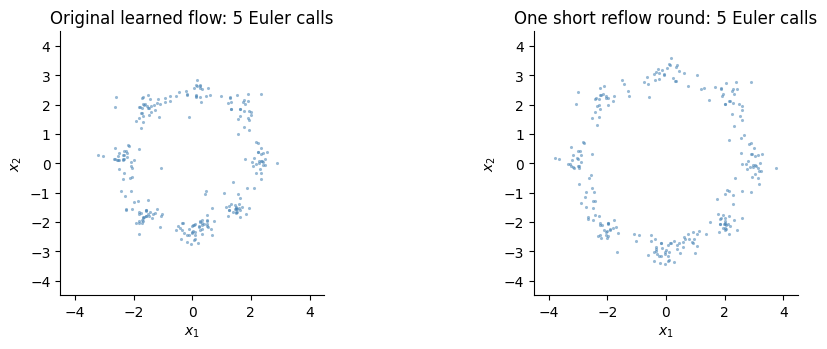

In [6]:
teacher_source = torch.randn(1024, 2, generator=torch.Generator().manual_seed(46))
teacher_target, _ = integrate(flow, teacher_source, torch.linspace(0, 1, 51), "heun")
torch.manual_seed(47)
reflow = TimeMLP(width=64, depth=2)
reflow.condition = Conditioning(64, 0, time_embedding="positional")
flow.condition = Conditioning(64, 0, time_embedding="positional")
optimizer = torch.optim.Adam(reflow.parameters(), lr=0.002)
g = torch.Generator().manual_seed(47)
for _step in range(800):
    index = torch.randint(len(teacher_source), (256,), generator=g)
    source, target = teacher_source[index], teacher_target[index]
    time = torch.rand(len(source), generator=g)
    state = (1 - time[:, None]) * source + time[:, None] * target
    loss = (reflow(state, time) - (target - source)).square().mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
reflow.eval()
heldout_noise = torch.randn(256, 2, generator=torch.Generator().manual_seed(48))
fig, axes = plt.subplots(1, 2)
for ax, (network, title) in zip(
    axes, [(flow, "Original learned flow"), (reflow, "One short reflow round")], strict=True
):
    _, trajectory = integrate(network, heldout_noise, torch.linspace(0, 1, 51), "heun")
    tau = torch.linspace(0, 1, len(trajectory))[:, None, None]
    chord = (1 - tau) * trajectory[0] + tau * trajectory[-1]
    print(
        title, "mean squared chord deviation:", (trajectory - chord).square().sum(-1).mean().item()
    )
    few_calls, _ = integrate(network, heldout_noise, torch.linspace(0, 1, 6), "euler")
    scatter(ax, few_calls, title + ": 5 Euler calls")
plt.tight_layout()
plt.show()

In [7]:
def explore_solver(steps=10, method="heun"):
    generated, _ = integrate(flow, initial, torch.linspace(0, 1, steps + 1), method)
    _fig, ax = plt.subplots()
    scatter(ax, generated, f"Learned flow: {method}, {steps} steps")
    plt.show()


if ENABLE_WIDGETS:
    from ipywidgets import interact

    interact(explore_solver, steps=(2, 60, 2), method=["euler", "heun", "rk4"])

## Exercises and worked answers

1. Explain why straight pair paths do not imply a constant learned velocity.
2. Compare Euler 20 steps and Heun 10 steps at equal call budget.
3. Change the pair path to trigonometric and use its derivatives in the target.

<details><summary>Worked answers</summary>

1. Compatible endpoint pairs depend on the observed state and time; their conditional average changes.
2. Both use 20 calls here. Compare field error and endpoint distributions; higher order only helps when field smoothness and model accuracy permit it.
3. For $a=\sin(\pi\tau/2)$ and $s=\cos(\pi\tau/2)$, target is $a'X+s'Z$, not $X-Z$.

</details>

**Animation:** [Learned flow](../assets/teaching/notebooks/03_learned_flow.gif).
**Continue:** [Guidance](04_guidance.ipynb), then [OT/interpolants/bridges](07_interpolants_transport_and_bridges.ipynb).
**Sources:** [Flow matching](https://arxiv.org/abs/2210.02747), [rectified flow](https://arxiv.org/abs/2209.03003).